[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/main/notebooks/f2_entropy_and_mutual_information.ipynb)

# Entropy and mutual information

* **Author**: simone.azeglio@gmail.com

* **Goal**: How much do the responses of a neuron tell about the stimulus, as one number?

* **Needs**: a CPU, no data.

* **Time**: about 5 s.

* **Track**: Foundations, notebook 2. The mutual information computed here is the quantity that Azeglio, Laquitaine, Ferrari, Chalk (NeurIPS 2026, arXiv 2605.06304) split over stimuli, and Laquitaine, Azeglio et al. (NeurIPS 2025) split into a local information.

* **Next**: notebook f3 asks how well two nearby stimuli can be told apart, with the Fisher information.

## 1. Setup

### 1.1. Install package

On Google Colab, install `multigeom`. Elsewhere this cell does nothing.

time: <1 sec

In [1]:
%%time

# on Google Colab install the package from PyPI, without its dependencies: Colab already
# has torch, numpy, scipy and matplotlib, and reinstalling torch is slow and can break
# the GPU runtime (nothing to do on your own machine)
import sys

if "google.colab" in sys.modules:
    %pip install -q --no-deps --pre multigeom

CPU times: user 5 μs, sys: 0 ns, total: 5 μs
Wall time: 7.87 μs


### 1.2. Imports

Import the packages, pick the device, compute in float64 and set the figure style. The device is `cuda` when there is a GPU and `cpu` otherwise, never `mps`, which has no float64.

time: <1 sec

In [2]:
%%time

import math

import matplotlib.pyplot as plt
import torch

from multigeom.lowdim import (
    entropy,
    mutual_information,
    posterior,
    response_density,
    response_grid,
    to_bits,
)

# run on the GPU when there is one
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_default_dtype(torch.float64)
print("device:", device)

# figure style of the Foundations notebooks: 9 pt text or more, no top or right spines
plt.rcParams.update(
    {
        "font.size": 10,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "legend.frameon": False,
    }
)
TEAL, ROSE, VIOLET, INK, GREY = "#2A8C7E", "#B23A62", "#5b3fd1", "#1a1a1a", "#8a8a8a"

device: cpu
CPU times: user 732 ms, sys: 86.6 ms, total: 819 ms
Wall time: 833 ms


### 1.3. Parameters of the series

The stimulus $x$ lies on $[-3, 3]$ with the uniform prior $p(x) = 1/6$, sampled on 1,201 grid points. The response is $r = \text{tuning}(x) + \sigma z$, with $z$ a standard Gaussian and $\sigma = 0.1$. Three neurons share this noise.

* The bell-shaped neuron, $f(x) = e^{-x^2/2}$.
* The monotonic twin, $m(x) = f(x)$ for $x < 0$ and $m(x) = 2 - f(x)$ for $x \ge 0$. It follows the bell up to the peak and then keeps rising to 2, so its slope has the same size as that of $f$ at every stimulus.
* The low-gain neuron, $0.5\, m(x)$.

`multigeom.lowdim` returns information in nats, computed with the natural logarithm $\ln$. `to_bits` divides by $\ln 2$ to give bits, the unit of this notebook.

time: <1 sec

In [3]:
%%time

X_MIN, X_MAX = -3.0, 3.0  # stimulus range
N_X = 1201  # stimulus grid points (step 0.005)
SIGMA = 0.1  # standard deviation of the response noise

x = torch.linspace(X_MIN, X_MAX, N_X, device=device)
dx = (x[1] - x[0]).item()
prior = torch.ones_like(x) / (N_X * dx)  # uniform, sums to 1 on the grid

bell = torch.exp(-(x**2) / 2)
twin = torch.where(x < 0, bell, 2 - bell)
low_gain = 0.5 * twin
neurons = {"bell-shaped": bell, "monotonic twin": twin, "low-gain": low_gain}
colours = {"bell-shaped": VIOLET, "monotonic twin": INK, "low-gain": GREY}

CPU times: user 342 μs, sys: 360 μs, total: 702 μs
Wall time: 1.64 ms


## 2. Uncertainty as a number of questions

The uncertainty about a stimulus can be counted as the number of yes/no questions needed to identify it. Eight equally likely bar orientations need three questions, so they hold 3 bits. When outcome $i$ has probability $p_i$, its surprise is $-\log_2 p_i$, and the entropy is the average surprise:

$$H(X) = -\sum_i p_i \log_2 p_i .$$

The next cell computes the entropy of eight equally likely outcomes and of a coin that lands heads with probability 0.9.

time: <1 sec

In [4]:
%%time


def entropy_bits(probabilities):
    """Entropy in bits of a discrete distribution."""
    p = torch.as_tensor(probabilities)
    p = p[p > 0]
    return -(p * torch.log2(p)).sum().item()


eight_orientations = entropy_bits(torch.full((8,), 1 / 8))
biased_coin = entropy_bits([0.9, 0.1])
print(f"eight equally likely orientations: {eight_orientations:.2f} bits")
print(f"coin with P(heads) = 0.9: {biased_coin:.2f} bits   (expected 0.47)")
print(f"surprise of heads {-math.log2(0.9):.2f}, of tails {-math.log2(0.1):.2f} bits")

eight equally likely orientations: 3.00 bits
coin with P(heads) = 0.9: 0.47 bits   (expected 0.47)
surprise of heads 0.15, of tails 3.32 bits
CPU times: user 397 μs, sys: 578 μs, total: 975 μs
Wall time: 2.85 ms


Heads carries 0.15 bits of surprise and the rare tails 3.32 bits, which count for one toss in ten. The average, 0.47 bits, is below the 1 bit of a fair coin.

## 3. The entropy of a density

For a continuous stimulus the sum becomes an integral over the prior density, the differential entropy:

$$H(X) = -\int p(x) \log_2 p(x)\, dx .$$

`entropy(density, step)` computes $-\int p \ln p\, dx$ as a Riemann sum on the grid, in nats. A uniform prior on an interval of width $L$ gives $\log_2 L$ bits. The entropy of a density depends on the units of the stimulus and can be negative. The next cell shows both, with the same stimulus in units 15 times smaller and with a uniform density on an interval of width 0.5.

time: <1 sec

In [5]:
%%time


def uniform_entropy_bits(width, n=N_X):
    """Entropy in bits of the uniform density on [0, width], on a grid of n points."""
    step = width / (n - 1)
    return to_bits(entropy(torch.full((n,), 1 / (n * step)), step)).item()


prior_entropy = to_bits(entropy(prior, dx)).item()
print(
    f"H(X), uniform prior on [-3, 3]: {prior_entropy:.3f} bits"
    f"   (log2 6 = {math.log2(6):.3f})"
)
print(
    f"same prior in units 15 times smaller: {uniform_entropy_bits(90.0):.2f} bits"
    "   (expected log2 90 = 6.49)"
)
print(
    f"uniform density on an interval of width 0.5: {uniform_entropy_bits(0.5):.2f} bits"
)

H(X), uniform prior on [-3, 3]: 2.586 bits   (log2 6 = 2.585)
same prior in units 15 times smaller: 6.49 bits   (expected log2 90 = 6.49)
uniform density on an interval of width 0.5: -1.00 bits
CPU times: user 351 μs, sys: 181 μs, total: 532 μs
Wall time: 533 μs


The grid value of $H(X)$ is 0.001 bits above $\log_2 6$, because the grid of 1,201 points with step 0.005 covers an interval of width 6.005. The difference of two entropies of the same variable does not depend on the units, because a change of units adds the same constant to both. This notebook only uses such differences.

## 4. The bits removed by one response

After a response $r$ the uncertainty is that of the posterior $p(x \mid r)$, with entropy $H(X \mid r)$. The bits removed by the response are $H(X) - H(X \mid r)$. We take the response $r = 0.6$ and compare the bell-shaped neuron with its twin. The figure shows the prior and the two posteriors.

time: <1 sec

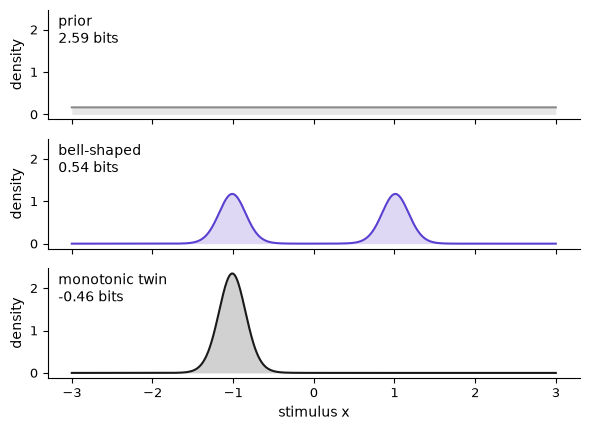

CPU times: user 91.9 ms, sys: 3.93 ms, total: 95.8 ms
Wall time: 96.2 ms


In [6]:
%%time

R_OBS = 0.6
post_bell = posterior(x, bell, prior, SIGMA, torch.tensor([R_OBS]))[:, 0]
post_twin = posterior(x, twin, prior, SIGMA, torch.tensor([R_OBS]))[:, 0]
h_post_bell = to_bits(entropy(post_bell, dx)).item()
h_post_twin = to_bits(entropy(post_twin, dx)).item()

rows = [("prior", prior, GREY), ("bell-shaped", post_bell, VIOLET)]
rows.append(("monotonic twin", post_twin, INK))
fig, axes = plt.subplots(3, 1, figsize=(6, 4.4), sharex=True, sharey=True)
for ax, (name, density, colour) in zip(axes, rows):
    ax.fill_between(x.cpu(), density.cpu(), color=colour, alpha=0.2, lw=0)
    ax.plot(x.cpu(), density.cpu(), color=colour)
    h = to_bits(entropy(density, dx)).item()
    ax.text(0.02, 0.7, f"{name}\n{h:.2f} bits", transform=ax.transAxes)
    ax.set_ylabel("density")
axes[-1].set_xlabel("stimulus x")
plt.tight_layout()
plt.show()

The bell-shaped posterior has two bumps, at $x = \pm 1.01$. The twin responds near 0.6 only left of the peak, because right of the peak its mean response is never below 1. Its posterior is the left bump alone, scaled up to hold the whole area. The next cell prints the entropies and the bits removed.

time: <1 sec

In [7]:
%%time

removed_bell = prior_entropy - h_post_bell
removed_twin = prior_entropy - h_post_twin
twin_mass_right = (post_twin * (x >= 0)).sum().item() * dx
bump_sd = ((post_twin * x**2).sum() * dx - ((post_twin * x).sum() * dx) ** 2).sqrt()

print(f"H(X | r = 0.6), bell-shaped: {h_post_bell:+.2f} bits   (expected +0.54)")
print(f"H(X | r = 0.6), twin:        {h_post_twin:+.2f} bits   (expected -0.46)")
print(
    f"bits removed: bell {removed_bell:.2f}, twin {removed_twin:.2f}"
    "   (expected 2.04, 3.04)"
)
print(f"difference: {h_post_bell - h_post_twin:.3f} bits   (expected 0.998)")
print(
    f"twin posterior right of the peak: {100 * twin_mass_right:.3f}%"
    "   (expected 0.015%)"
)
print(f"standard deviation of the twin's bump: {bump_sd.item():.2f}   (expected 0.18)")

H(X | r = 0.6), bell-shaped: +0.54 bits   (expected +0.54)
H(X | r = 0.6), twin:        -0.46 bits   (expected -0.46)
bits removed: bell 2.04, twin 3.04   (expected 2.04, 3.04)
difference: 0.998 bits   (expected 0.998)
twin posterior right of the peak: 0.015%   (expected 0.015%)
standard deviation of the twin's bump: 0.18   (expected 0.18)
CPU times: user 301 μs, sys: 215 μs, total: 516 μs
Wall time: 684 μs


The two posteriors differ by almost exactly one bit. Splitting a density into two equal copies, one on each side of the peak, adds the uncertainty of one fair question: is the stimulus left or right of the peak? The bell-shaped neuron cannot answer it. The difference is 0.998 bits and not 1, because the twin's posterior keeps 0.015% of its area right of the peak.

The twin's entropy is negative because its bump is narrow. A Gaussian density with standard deviation $s$ has entropy $\tfrac{1}{2}\log_2(2\pi e\, s^2)$, which is negative when $s < 1/\sqrt{2\pi e} = 0.24$, and this bump has $s = 0.18$.

Other responses remove other amounts. The next cell repeats the computation for the bell-shaped neuron and the responses 0.3 and 1.0.

time: <1 sec

In [8]:
%%time

other_responses = torch.tensor([0.3, 1.0])
h_other = to_bits(entropy(posterior(x, bell, prior, SIGMA, other_responses), dx))
for r_obs, h in zip(other_responses.tolist(), h_other.tolist()):
    print(f"r = {r_obs}: {h:.2f} bits left, {prior_entropy - h:.2f} bits removed")
print(
    "expected: r = 0.3 -> 1.15 left, 1.44 removed; r = 1.0 -> 0.40 left, 2.19 removed"
)

r = 0.3: 1.15 bits left, 1.44 bits removed
r = 1.0: 0.40 bits left, 2.19 bits removed
expected: r = 0.3 -> 1.15 left, 1.44 removed; r = 1.0 -> 0.40 left, 2.19 removed
CPU times: user 395 μs, sys: 129 μs, total: 524 μs
Wall time: 503 μs


## 5. Mutual information

The mutual information averages the bits removed over all responses, each weighted by how often it occurs, that is by the marginal density $p(r) = \int p(r \mid x)\, p(x)\, dx$:

$$I(R; X) = H(X) - H(X \mid R), \qquad H(X \mid R) = \int p(r)\, H(X \mid r)\, dr .$$

$H(X \mid R)$ is the conditional entropy, the average uncertainty left once a response is seen. `mutual_information(x, tuning, prior, sigma)` computes $I(R; X)$ in nats by quadrature on the stimulus grid and on a response grid of 361 points. The figure shows the three tuning curves with a band of $\pm\sigma$ and their mutual information.

time: <1 sec

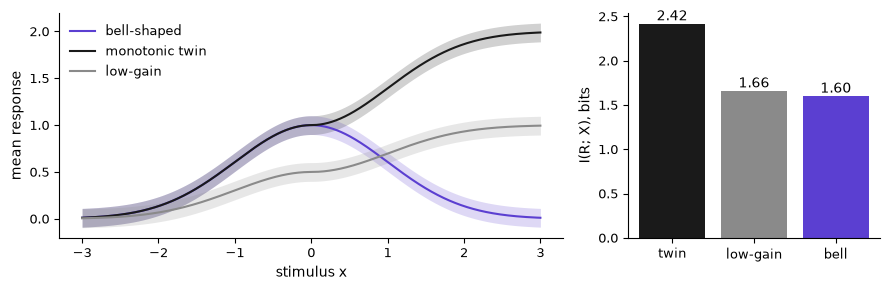

bell-shaped     1.603 bits
monotonic twin  2.419 bits
low-gain        1.662 bits
expected: bell-shaped 1.603, monotonic twin 2.419, low-gain 1.662
CPU times: user 98.1 ms, sys: 12 ms, total: 110 ms
Wall time: 106 ms


In [9]:
%%time

mi_bits = {
    name: to_bits(mutual_information(x, tuning, prior, SIGMA)).item()
    for name, tuning in neurons.items()
}

fig, (ax, ax_bar) = plt.subplots(
    1, 2, figsize=(9, 3), gridspec_kw={"width_ratios": [2, 1]}
)
for name, tuning in neurons.items():
    t = tuning.cpu()
    ax.fill_between(x.cpu(), t - SIGMA, t + SIGMA, color=colours[name], alpha=0.2, lw=0)
    ax.plot(x.cpu(), t, color=colours[name], label=name)
ax.set_xlabel("stimulus x")
ax.set_ylabel("mean response")
ax.legend(loc="upper left")
order = ["monotonic twin", "low-gain", "bell-shaped"]
bars = ax_bar.bar(
    range(3), [mi_bits[n] for n in order], color=[colours[n] for n in order]
)
ax_bar.bar_label(bars, fmt="%.2f")
ax_bar.set_xticks(range(3), ["twin", "low-gain", "bell"])
ax_bar.set_ylabel("I(R; X), bits")
plt.tight_layout()
plt.show()

for name, value in mi_bits.items():
    print(f"{name:15s} {value:.3f} bits")
print("expected: bell-shaped 1.603, monotonic twin 2.419, low-gain 1.662")

The twin carries 2.42 bits and the bell-shaped neuron 1.60 bits, although their slopes have the same size at every stimulus. Halving the gain of the twin costs 0.76 bits, and folding the twin into a bell costs 0.82 bits.

The next cell checks the definition on the same grids. It computes the posterior of every response on the response grid, averages their entropies with the weights $p(r)$, and subtracts the result from $H(X)$. It also measures the uncertainty left about the side of the peak, $x < 0$ or $x \ge 0$, averaged over responses.

time: <1 sec

In [10]:
%%time


def conditional_entropies(tuning):
    """(H(X | R), H(side | R)) in bits, by quadrature over the response grid."""
    r = response_grid(tuning, SIGMA, n_r=361)
    dr = (r[1] - r[0]).item()
    p_r = (prior[:, None] * response_density(tuning, SIGMA, r)).sum(0) * dx
    post = posterior(x, tuning, prior, SIGMA, r)  # [N_X, 361]
    h_x_given_r = to_bits(entropy(post, dx))
    right = ((post * (x >= 0)[:, None]).sum(0) * dx).clamp(1e-300, 1 - 1e-16)
    h_side = -(right * right.log2() + (1 - right) * (1 - right).log2())
    return (p_r * h_x_given_r).sum().item() * dr, (p_r * h_side).sum().item() * dr


side_left = {}
for name, tuning in neurons.items():
    h_cond, side_left[name] = conditional_entropies(tuning)
    print(f"{name:15s} H(X) - H(X | R) = {prior_entropy - h_cond:.3f} bits")
print(
    f"side of the peak left uncertain: bell {side_left['bell-shaped']:.2f} bits,"
    f" twin {side_left['monotonic twin']:.2f} bits   (expected 1, 0.18)"
)

bell-shaped     H(X) - H(X | R) = 1.603 bits
monotonic twin  H(X) - H(X | R) = 2.419 bits
low-gain        H(X) - H(X | R) = 1.662 bits
side of the peak left uncertain: bell 1.00 bits, twin 0.18 bits   (expected 1, 0.18)
CPU times: user 22.4 ms, sys: 10.1 ms, total: 32.5 ms
Wall time: 20.8 ms


The two computations agree. The bell-shaped neuron leaves the side of the peak fully uncertain, one bit for every response. The twin leaves 0.18 bits on average, from stimuli close to the peak where its two sides give responses near 1. The gap $1 - 0.18 = 0.82$ bits is the difference between the two neurons.

## 6. The response side of the same number

The mutual information is symmetric in the stimulus and the response:

$$I(R; X) = H(R) - H(R \mid X).$$

With Gaussian noise the response to a fixed stimulus has entropy $\tfrac{1}{2}\log_2(2\pi e\, \sigma^2)$ whatever the stimulus, so $H(R \mid X)$ is the entropy of the noise alone. A neuron is informative when its responses, pooled over all stimuli, spread widely compared with the noise.

time: <1 sec

In [11]:
%%time

noise_entropy = 0.5 * math.log2(2 * math.pi * math.e * SIGMA**2)
response_entropy = {}
for name, tuning in neurons.items():
    r = response_grid(tuning, SIGMA, n_r=361)
    p_r = (prior[:, None] * response_density(tuning, SIGMA, r)).sum(0) * dx
    response_entropy[name] = to_bits(entropy(p_r, (r[1] - r[0]).item())).item()
    print(
        f"{name:15s} H(R) = {response_entropy[name]:.2f} bits,"
        f" H(R) - H(R | X) = {response_entropy[name] - noise_entropy:.3f} bits"
    )
print(f"H(R | X) = {noise_entropy:.2f} bits   (expected -1.27)")
print("expected H(R): twin 1.14, low-gain 0.39, bell-shaped 0.33")

bell-shaped     H(R) = 0.33 bits, H(R) - H(R | X) = 1.603 bits
monotonic twin  H(R) = 1.14 bits, H(R) - H(R | X) = 2.419 bits
low-gain        H(R) = 0.39 bits, H(R) - H(R | X) = 1.662 bits
H(R | X) = -1.27 bits   (expected -1.27)
expected H(R): twin 1.14, low-gain 0.39, bell-shaped 0.33
CPU times: user 7.73 ms, sys: 3.37 ms, total: 11.1 ms
Wall time: 6.86 ms


The responses of the twin spread from 0 to 2, so $H(R)$ is largest for it. The bell-shaped neuron has the smallest $H(R)$, because its responses all lie between 0 and 1 and pile up near 0.

## 7. Try it

* Double the noise to $\sigma = 0.2$. Look at how much each neuron loses.
* Double the gain and the noise together, $2m(x)$ with $2\sigma$. The response is the old one multiplied by 2, so the mutual information should not change.
* Replace the uniform prior by a Gaussian prior with standard deviation 1, cut to $[-3, 3]$ and normalised on the grid. Look at whether the gap between the bell-shaped neuron and its twin stays near 0.82 bits.

The next cell carries out the first change.

time: <1 sec

In [12]:
%%time

SIGMA_DOUBLED = 0.2
mi_doubled = {
    name: to_bits(mutual_information(x, tuning, prior, SIGMA_DOUBLED)).item()
    for name, tuning in neurons.items()
}
for name, value in mi_doubled.items():
    print(f"{name:15s} {mi_bits[name]:.2f} -> {value:.2f} bits")
print("expected at sigma = 0.2: bell-shaped 0.94, monotonic twin 1.66")

bell-shaped     1.60 -> 0.94 bits
monotonic twin  2.42 -> 1.66 bits
low-gain        1.66 -> 0.94 bits
expected at sigma = 0.2: bell-shaped 0.94, monotonic twin 1.66
CPU times: user 14.8 ms, sys: 6.01 ms, total: 20.8 ms
Wall time: 12.6 ms


At $\sigma = 0.2$ the twin carries 1.66 bits, the value of the low-gain neuron at $\sigma = 0.1$. The low-gain neuron is the twin with its response halved, which is the same code as the twin with doubled noise.

**Next**: [notebook f3](f3_fisher_information.ipynb) asks how well two nearby stimuli can be told apart.